# Q1C | Analyze Relationships Between Attributes

> *Analyze the relationships between the data attributes, and between the data attributes and label. This involves computing the Pearson Correlation Coefficient (PCC) and generating scatter plots.*

---

#### IMPORTANT

This notebook uses only the `train` dataset, so no analysis or treatment decision is influenced by the test data (`data snooping`). Every statistic below is computed on the training rows only.

# Answer Summary

**PCC and scatter plots:** a scatter matrix of every attribute and `Life Ladder`, a Pearson (lower) vs Spearman (upper) correlation matrix, and a check for redundant and complementary attributes. Then the shape of each attribute's relationship with `Life Ladder` is tested: reshaped versions of the attribute (hinge, indicator, transform) are scored against the raw value in a single attribute linear regression, on the same 20 cross validation folds.

**Attributes vs label**

| Attribute | Pearson r | Spearman rho | Shape of the relationship | r2, raw | r2, with the shape |
|---|---|---|---|---|---|
| Log GDP per capita | 0.79 | 0.80 | Two bends, near 10.3 and 10.9 | 0.617 | 0.655 |
| Healthy life expectancy | 0.75 | 0.79 | Flat below about 57, rising above | 0.562 | 0.614 |
| Social support | 0.70 | 0.75 | Shallow, then steep above about 0.84 | 0.493 | 0.554 |
| Freedom to make life choices | 0.53 | 0.54 | Shallow, then steep above about 0.80 | 0.276 | 0.315 |
| Positive affect | 0.53 | 0.54 | Close to linear, with a small jump near 0.75 | 0.282 | 0.294 |
| Perceptions of corruption | -0.43 | -0.32 | A level shift in the low tail, below about 0.58 | 0.178 | 0.190 |
| Negative affect | -0.30 | -0.26 | Flat until about 0.2, falling above | 0.088 | 0.099 |
| Generosity | 0.19 | 0.17 | A jump near 0.09 | 0.033 | 0.056 |

r2 is the mean over the folds. "With the shape" has its threshold searched inside each fold.

- **Strength:** the first three rows are strong, the next three moderate and the last two weak.
- **PCC understates the curved relationships.** Spearman is above Pearson for Social support and Healthy life expectancy, and their scatter plots bend. Corruption is the reverse: its straight line leans on the low tail.
- **A straight line is never the best description.** Every attribute has a shape that beats its raw value by more than the noise threshold. The gains are largest for Social support and Healthy life expectancy, and smallest for Positive affect, Corruption and Negative affect.

**Attributes vs attributes**

- **One redundant pair:** Log GDP and Healthy life expectancy (r = 0.85), the only pair above 0.7. Log GDP and Social support (0.70) sit right at that threshold.
- **The three strong attributes overlap** (0.62 to 0.85 with each other), so their separate strengths do not add up.
- **Positive affect and Freedom add the most on top of them.** They correlate only 0.30 to 0.42 with the three strong attributes, and adding Positive affect to Log GDP lifts the multiple correlation R with `Life Ladder` from 0.787 to 0.847.

**Carried forward** to a model that uses all the attributes:

- **Use each attribute's shape from the table** in place of its raw value. For Positive affect the raw value stays the fallback, since its gain is small.
- **Test dropping Generosity and Negative affect,** which stay weak whatever the shape (r2 0.056 and 0.099).
- **Keep one of Log GDP and Healthy life expectancy, or use a penalty such as Ridge.**
- **Confirm every gain again.** Each one was measured with a single attribute in the model.

---

# Imports

In [1]:
# Imports
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.preprocessing import FunctionTransformer, PowerTransformer

from Q1.consts import *

from utils import (
	read_csv_to_df,
	STATISTICS,
	PLOTTING,
	SCORING,
	FEATURES,
	PIPELINES,
)

# Fetch Data

In [2]:
train_df = read_csv_to_df(path=TRAIN_PATH)

# Attribute vs Attribute and Label

## Scatter Matrix

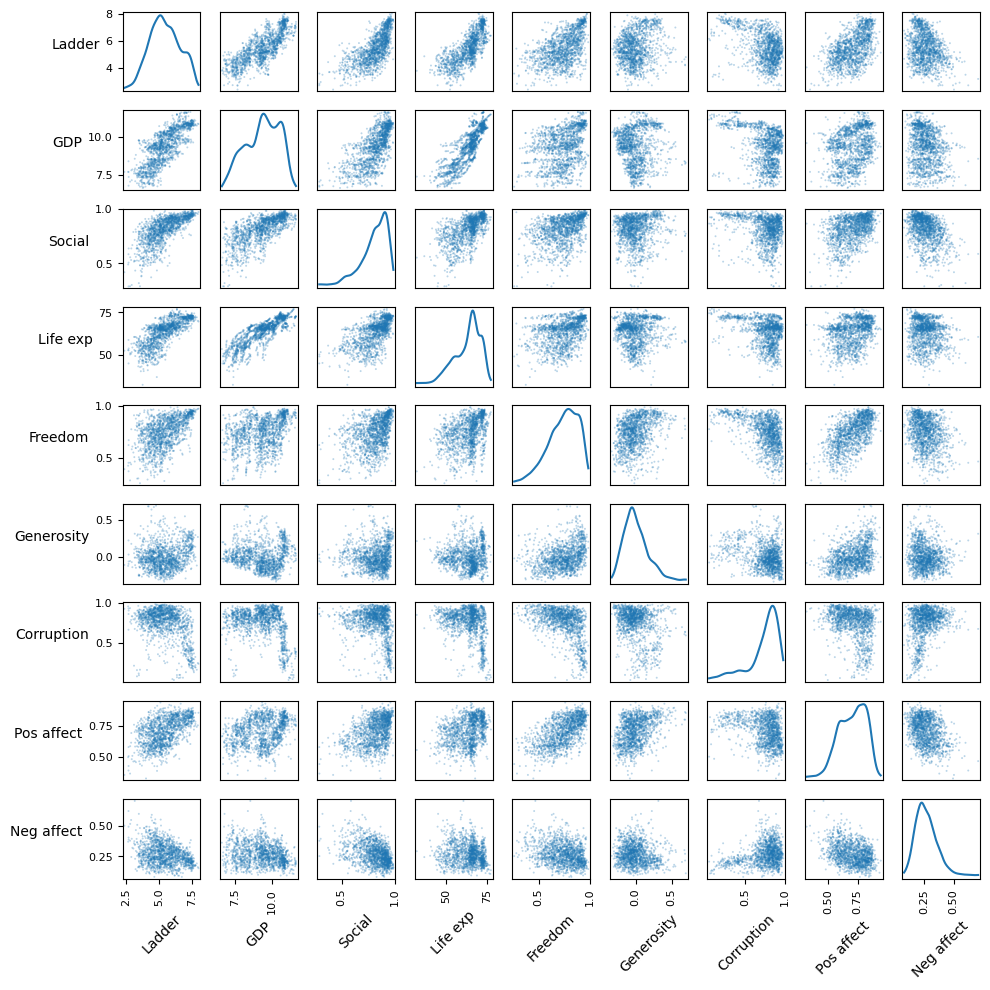

In [3]:
PLOTTING.scatter_matrix(df=train_df, labels=SHORT_NAMES);

### Notes / Observations

- **Three attributes track the label in a tight band:** Log GDP, Healthy life expectancy and Social support. Freedom and Positive affect rise in a looser cloud, Corruption and Negative affect fall, and Generosity shows no clear direction.
- **Several of the label panels bend.** Social support and Healthy life expectancy are flatter at the low end and steeper at the top, which a straight line cannot follow. The Single Attribute Interventions below test those shapes.
- **Corruption's panels are L shaped.** Most rows crowd near the top of its range, and the low values appear only at high Log GDP, Healthy life expectancy and Life Ladder, so its relationships rest on a small group of rows.

## Correlation

<Axes: title={'center': 'Pearson (lower) vs Spearman (upper) Correlation Matrix (train)'}>

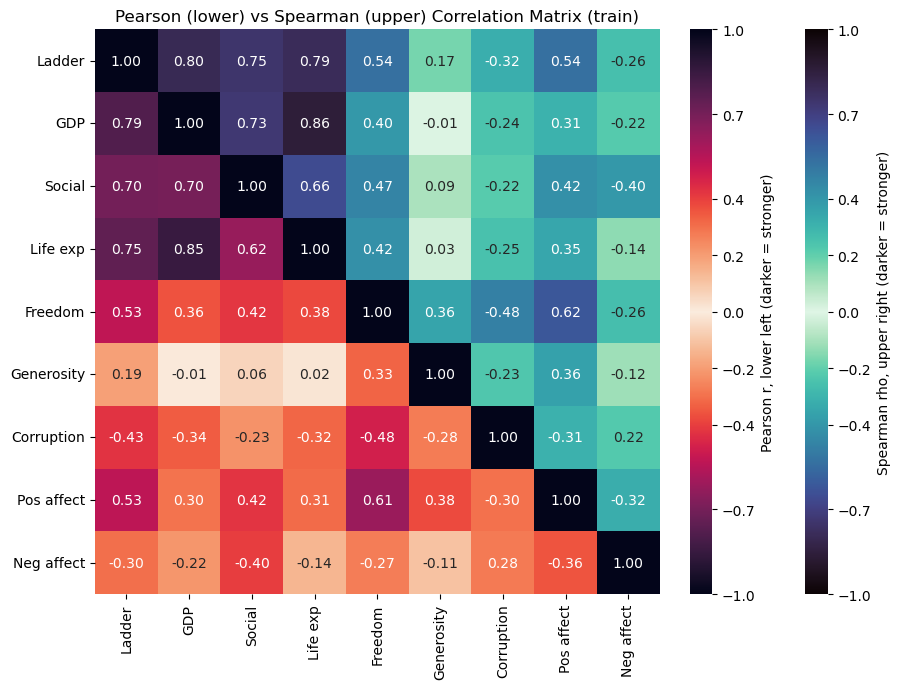

In [4]:
PLOTTING.correlation_matrix(
      pearson=train_df.corr(),
      spearman=train_df.corr(method='spearman'),
      labels=SHORT_NAMES,
      title='Pearson (lower) vs Spearman (upper) Correlation Matrix (train)',
)

### Notes / Observations

A gap between Pearson r (lower left) and Spearman rho (upper right) points to a curved relationship. Pearson r measures how closely the points follow a straight line. Spearman rho is the same calculation on the ranks of the values, so it only asks whether one attribute keeps rising (or keeps falling) as the other rises, and ignores by how much. A relationship that keeps rising but bends still has its ranks in order, so rho stays high, while r drops because the points leave the straight line. The reverse gap (r larger in size than rho) points to a few far out values steering the straight line, because ranking removes how far out they are.

- **Strength with `Life Ladder` (Pearson):** strong for Log GDP (0.79), Healthy life expectancy (0.75) and Social support (0.70). Moderate for Freedom (0.53), Positive affect (0.53) and Corruption (-0.43). Weak for Negative affect (-0.30) and Generosity (0.19).
- **Pearson understates the curved ones.** Spearman is higher for Social support (0.75 vs 0.70) and Healthy life expectancy (0.79 vs 0.75). Corruption is the reverse (-0.32 vs -0.43): its straight line fit leans on the low tail.
- **The strong attributes overlap:** Log GDP with Healthy life expectancy (0.85) and with Social support (0.70), and Social support with Healthy life expectancy (0.62). Their separate strengths do not add up.
- **Positive affect and Freedom are the most independent of those three** (0.30 to 0.42 with each of them) while still moderate with the label.

### Collinearity

`collinearity_df` gives each pair of attributes one of two outcomes:

| `outcome` | When | What it means |
|---|---|---|
| `redundant: keep one, or use regularization` | \|r\| between the two attributes is above 0.7 | The two say close to the same thing. Drop one of them, or keep both and use a regularized model (Ridge, Lasso or Elastic Net). |
| `not redundant` | \|r\| is at or below 0.7 | The pair is not flagged. Each attribute carries enough of its own information to keep both. |

- **The sign is ignored.** A pair at r = -0.85 is as redundant as one at 0.85.
- **The check is strict and uses the rounded r.** A pair that rounds to exactly 0.700 is `not redundant`.
- **Only the redundant pairs are shown** (`filter=True`), so an empty table means no pair crossed the threshold. `filter=False` shows every pair. Fewer than 2 columns raises a `ValueError`.

In [5]:
STATISTICS.collinearity_df(df=train_df.drop(columns=TARGET),
													 # feature_pearson_threshold=0.7, filter=True # defaults
)

,rows used,Pearson r between features,|r| between features > 0.7,outcome
Log GDP per capita + Healthy life expectancy at birth,1509,0.851,True,"redundant: keep one, or use regularization"


#### Combined Gain

`combination_gain_df` gives each pair or triple one of two outcomes:

| `outcome` | When | What it means |
|---|---|---|
| `keep together` | Cohen f² is at or above 0.15 | The added attribute explains enough of what the baseline leaves unexplained. The baseline is the best subset that leaves one attribute out, so dropping any other attribute would cost at least as much. |
| `baseline is enough` | Cohen f² is below 0.15 | The added attribute brings little that the baseline does not already have. The baseline alone does nearly as well. |

- **The outcome is about the added attribute.** The baseline is the subset, one attribute short, with the highest Pearson R. f² is what the left out attribute adds on top of it: (R² all features - R² baseline) / (1 - R² all features).
- **The check is inclusive and uses the rounded f².** An f² of exactly 0.150 is `keep together`.
- **An undefined f² reads `baseline is enough`.** That happens when R cannot be computed, ex a constant label on the rows used.
- **Only the `keep together` rows are shown** (`filter=True`), so an empty table means no combination reached the threshold. `filter=False` shows every combination. A `size` below 2 or above the number of columns raises a `ValueError`.

In [6]:
STATISTICS.combination_gain_df(df=train_df, target=train_df[TARGET],
															 # size=2, cohen_f2_threshold=0.15, filter=True # defaults
)

,rows used,baseline features,added feature,baseline Pearson R,all features Pearson R,Pearson R gain,baseline Spearman rho,all features Spearman rho,Spearman rho gain,cohen f²,cohen f² ≥ 0.15,outcome
Log GDP per capita + Positive affect,1516,Log GDP per capita,Positive affect,0.787,0.847,0.060,0.800,0.858,0.058,0.346,True,keep together
Healthy life expectancy at birth + Positive affect,1505,Healthy life expectancy at birth,Positive affect,0.753,0.816,0.063,0.791,0.840,0.049,0.296,True,keep together
Social support + Healthy life expectancy at birth,1512,Healthy life expectancy at birth,Social support,0.751,0.810,0.060,0.788,0.847,0.060,0.271,True,keep together
Log GDP per capita + Freedom to make life choices,1511,Log GDP per capita,Freedom to make life choices,0.788,0.830,0.042,0.802,0.839,0.037,0.219,True,keep together
Healthy life expectancy at birth + Freedom to make life choices,1500,Healthy life expectancy at birth,Freedom to make life choices,0.752,0.798,0.046,0.790,0.828,0.038,0.197,True,keep together
Social support + Perceptions of corruption,1468,Social support,Perceptions of corruption,0.709,0.760,0.051,0.755,0.760,0.005,0.177,True,keep together
Social support + Positive affect,1540,Social support,Positive affect,0.704,0.750,0.046,0.748,0.783,0.035,0.153,True,keep together
Social support + Freedom to make life choices,1532,Social support,Freedom to make life choices,0.705,0.750,0.045,0.748,0.779,0.031,0.151,True,keep together


In [7]:
STATISTICS.combination_gain_df(df=train_df, target=train_df[TARGET], size=3,
															 # cohen_f2_threshold=0.15, filter=True # defaults
)

,rows used,baseline features,added feature,baseline Pearson R,all features Pearson R,Pearson R gain,baseline Spearman rho,all features Spearman rho,Spearman rho gain,cohen f²,cohen f² ≥ 0.15,outcome
Social support + Healthy life expectancy at birth + Positive affect,1503,Healthy life expectancy at birth + Positive af...,Social support,0.816,0.844,0.028,0.84,0.872,0.032,0.164,True,keep together


#### Notes / Observations

The gain tables list the pairs and triples where the last attribute added lifts the multiple correlation R with `Life Ladder` by a Cohen f² of at least 0.15. They are fit and scored on the same rows, so the gains are optimistic.

- **One redundant pair:** Log GDP and Healthy life expectancy (r = 0.851), the only pair above 0.7. A model that uses both should keep one or use a penalty such as Ridge. Log GDP and Social support (0.70 in the correlation matrix) sit right at the threshold.
- **Positive affect and Freedom supply what the strong attributes lack.** One of them is the added attribute in most of the eight pairs, led by Log GDP + Positive affect (R 0.787 to 0.847, f² 0.346).
- **Corruption's gain is fragile.** Social support + Corruption gains 0.051 in Pearson R but only 0.005 in Spearman rho.
- **Gains shrink after two attributes.** Only one triple clears the threshold: Social support + Healthy life expectancy + Positive affect (f² 0.164).

# Attribute Interventions

## Single Attribute Interventions

Interventions on a single attribute aimed at improving the attribute's linear relationship & predictability with the target

### Method

- **Rows:** rows missing the attribute being tested are dropped. Rows missing other attributes are kept.
- **Folds:** every intervention is a `Pipeline` of a transform then `LinearRegression`, fit inside each training fold and scored on the same 20 folds (4-fold cross validation over the 5 `SEEDS`).
- **A, the baseline:** the raw value alone, `Life Ladder = a + b·x`. Every other intervention has to beat it. If the shape an intervention adds is not real, it ties with A.
- **fixed** variants use the threshold t that Q1B reported. Q1B found it on all the training rows, so a fixed variant can look optimistic.
- **nested** variants search t inside each training fold (inner 4-fold CV, at least 5% of the fold's rows on each side of t), over a grid set in each attribute's setup cell. The picked t never sees the validation fold.

**Noise threshold (Δrmse vs A)**

- Δ is the mean of the per-fold rmse differences d (intervention minus A). Negative means lower error than A.
- SE is the standard error of Δ. The folds share most of their training rows, so they are not independent results, and the SE is widened for that with the Nadeau and Bengio correction: `SE = sqrt(var(d) · (1/folds + n_test/n_train))`.
- `verdict`:
  - **within noise:** Δ is within 1 SE of 0, so A is kept as the simpler model.
  - **candidate:** Δ is below -1 SE.
  - **worse:** Δ is above +1 SE.

**Results**

- Each attribute ends with its findings, what to **Carry forward** and, where something tested is dropped, what to **Ignore**.
- Only **candidate** interventions carry forward, with t searched in each fold. Every gain is a single attribute gain, so it has to hold up again once the other attributes are in the model.

### Perceptions of Corruption

Tests Q1B's rank 1 as B (raw value plus a low value indicator near 0.58) and rank 2 as C (raw value plus a hinge near 0.86). Rank 3, the raw value alone, is A.

In [8]:
poc_col = COLUMNS['POC']['col']
poc_df = train_df[[poc_col, TARGET]].dropna(subset=[poc_col])
poc_X = poc_df[[poc_col]]
poc_y = poc_df[TARGET]

poc_folds = PIPELINES.make_folds(poc_X, seeds=SEEDS)
poc_results = {}

print(f"rows used: {len(poc_df)} of {len(train_df)}")
print(f"folds: {len(poc_folds)}")

rows used: 1473 of 1559
folds: 20


#### Intervention A | Baseline (raw)

In [9]:
poc_results["A"] = PIPELINES.evaluate_pipeline(
	Pipeline([("model", LinearRegression())]),
	X=poc_X, y=poc_y, folds=poc_folds,
)
display(SCORING.results_df({k: poc_results[k] for k in ["A"]}, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
A,1.017,0.178,0.0,NaN,baseline


#### Intervention B | Raw + low value indicator

`[x, 1 if x < t else 0]`

Targets the level shift in Q1B's box plot: the rows below the step at 0.58 sit higher on Life Ladder than the rows at or above it.

In [10]:
poc_b_pipeline = Pipeline([("features", FEATURES.Indicator(t=0.58, keep_raw=True)), ("model", LinearRegression())])

poc_results["B fixed (t=0.58)"] = PIPELINES.evaluate_pipeline(
	poc_b_pipeline,
	X=poc_X, y=poc_y, folds=poc_folds,
)
poc_results["B nested"] = PIPELINES.evaluate_pipeline(
	FEATURES.nested_threshold(poc_b_pipeline, param="features__t"),
	X=poc_X, y=poc_y, folds=poc_folds, return_estimator=True,
)
display(SCORING.results_df({k: poc_results[k] for k in ["A", "B fixed (t=0.58)", "B nested"]}, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
B fixed (t=0.58),1.006,0.195,-0.011,0.004,candidate
B nested,1.009,0.190,-0.007,0.004,candidate
A,1.017,0.178,0.000,NaN,baseline


In [11]:
# threshold picked by the inner search in each of the 20 folds
poc_b_picked = FEATURES.picked_thresholds(poc_results["B nested"]["estimator"], param="features__t")
display(pd.Series(poc_b_picked).value_counts().sort_index().rename_axis("B nested picked t").to_frame("folds"))

,folds
B nested picked t,
0.51,11
0.53,4
0.57,4
0.63,1


#### Intervention C | Raw + hinge

`[x, max(0, t - x)]`

Targets the bend in Q1B's LOWESS, a steep fall across the low tail and a nearly flat top, which Q1B's hinge fit places near 0.86.

In [12]:
poc_c_pipeline = Pipeline([("features", FEATURES.LowHinge(t=0.86, keep_raw=True)), ("model", LinearRegression())])

poc_results["C fixed (t=0.86)"] = PIPELINES.evaluate_pipeline(
	poc_c_pipeline,
	X=poc_X, y=poc_y, folds=poc_folds,
)
poc_results["C nested"] = PIPELINES.evaluate_pipeline(
	FEATURES.nested_threshold(poc_c_pipeline, param="features__t"),
	X=poc_X, y=poc_y, folds=poc_folds, return_estimator=True,
)
display(SCORING.results_df({k: poc_results[k] for k in ["A", "C fixed (t=0.86)", "C nested"]}, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
C fixed (t=0.86),1.009,0.190,-0.008,0.003,candidate
C nested,1.015,0.180,-0.002,0.003,within noise
A,1.017,0.178,0.000,NaN,baseline


In [13]:
# threshold picked by the inner search in each of the 20 folds
poc_c_picked = FEATURES.picked_thresholds(poc_results["C nested"]["estimator"], param="features__t")
display(pd.Series(poc_c_picked).value_counts().sort_index().rename_axis("C nested picked t").to_frame("folds"))

,folds
C nested picked t,
0.29,2
0.31,4
0.33,2
0.83,1
0.85,5
0.87,6


#### Comparison

In [14]:
display(SCORING.results_df(poc_results, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
B fixed (t=0.58),1.006,0.195,-0.011,0.004,candidate
C fixed (t=0.86),1.009,0.190,-0.008,0.003,candidate
B nested,1.009,0.190,-0.007,0.004,candidate
C nested,1.015,0.180,-0.002,0.003,within noise
A,1.017,0.178,0.000,NaN,baseline


#### Results

- **The gain is real but small.** B fixed lowers rmse from 1.017 to 1.006 and C fixed to 1.009, both candidates (changes of -0.011 and -0.008 against SEs of 0.004 and 0.003).
- **Only the indicator holds up when t is searched.** B nested stays a candidate, and it picked t between 0.51 and 0.63 in every fold, around Q1B's 0.58. C nested is within noise, and its picks split between 0.29 to 0.33 and 0.83 to 0.87, so the folds do not agree on where the bend is.

**Carry forward**

- **B (raw + indicator).**

**Ignore**

- **C (raw + hinge).** It only helps at Q1B's 0.86, a threshold found on all the training rows.

### Social Support

Tests Q1B's rank 1 as B (raw value plus a hinge near 0.84) and rank 2 as C (a transform that stretches the top end, using Yeo-Johnson, Q1B's first choice).

In [15]:
ss_col = COLUMNS['SS']['col']
ss_df = train_df[[ss_col, TARGET]].dropna(subset=[ss_col])
ss_X = ss_df[[ss_col]]
ss_y = ss_df[TARGET]

ss_folds = PIPELINES.make_folds(ss_X, seeds=SEEDS)
ss_results = {}

print(f"rows used: {len(ss_df)} of {len(train_df)}")
print(f"folds: {len(ss_folds)}")

rows used: 1549 of 1559
folds: 20


#### Intervention A | Baseline (raw)

In [16]:
ss_results["A"] = PIPELINES.evaluate_pipeline(
	Pipeline([("model", LinearRegression())]),
	X=ss_X, y=ss_y, folds=ss_folds,
)
display(SCORING.results_df({k: ss_results[k] for k in ["A"]}, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
A,0.792,0.493,0.0,NaN,baseline


#### Intervention B | Raw + hinge

`[x, max(0, x - t)]`

Targets the bend in Q1B's LOWESS, shallow below about 0.8 and steep above, which Q1B's hinge fit places at 0.84 (slope 4.06 below, 14.61 above).

In [17]:
ss_b_pipeline = Pipeline([("features", FEATURES.HighHinge(t=0.84, keep_raw=True)), ("model", LinearRegression())])

ss_results["B fixed (t=0.84)"] = PIPELINES.evaluate_pipeline(
	ss_b_pipeline,
	X=ss_X, y=ss_y, folds=ss_folds,
)
ss_results["B nested"] = PIPELINES.evaluate_pipeline(
	FEATURES.nested_threshold(ss_b_pipeline, param="features__t"),
	X=ss_X, y=ss_y, folds=ss_folds, return_estimator=True,
)
display(SCORING.results_df({k: ss_results[k] for k in ["A", "B fixed (t=0.84)", "B nested"]}, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
B fixed (t=0.84),0.739,0.558,-0.053,0.008,candidate
B nested,0.742,0.554,-0.050,0.008,candidate
A,0.792,0.493,0.000,NaN,baseline


In [18]:
# threshold picked by the inner search in each of the 20 folds
ss_b_picked = FEATURES.picked_thresholds(ss_results["B nested"]["estimator"], param="features__t")
display(pd.Series(ss_b_picked).value_counts().sort_index().rename_axis("B nested picked t").to_frame("folds"))

,folds
B nested picked t,
0.79,6
0.81,1
0.83,4
0.85,9


#### Intervention C | Yeo-Johnson

`[YJ(x)]`

Targets the same bend with one column and no threshold. The transform's power is fit inside each training fold and stretches the crowded top end, where Q1B's LOWESS is steep.

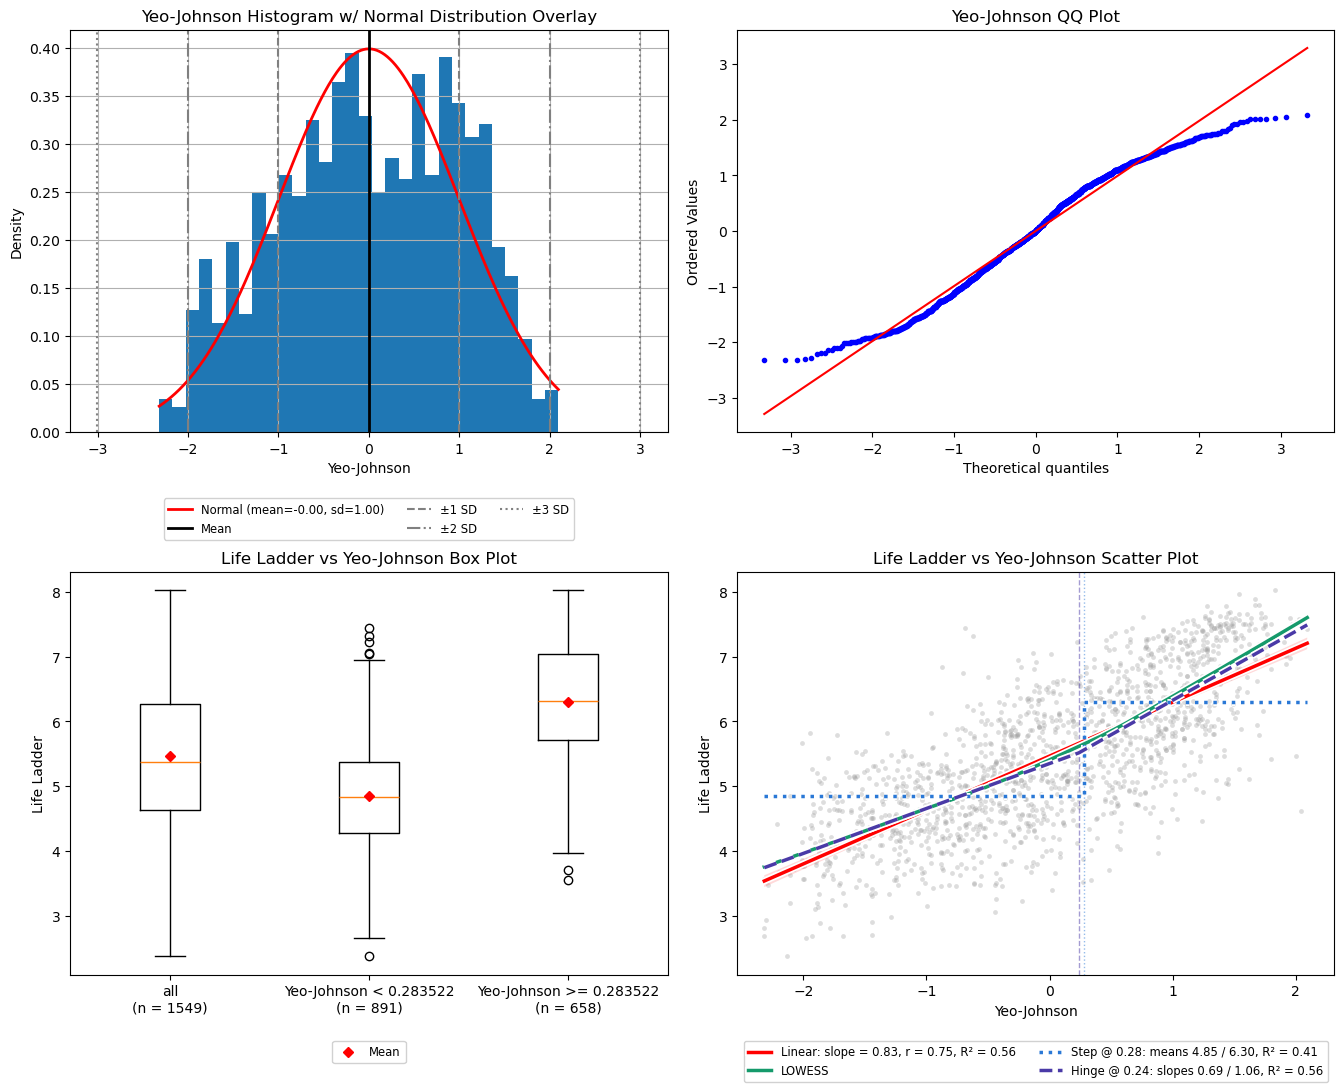

In [19]:
# fit on all ss_df rows, for illustration only (the scores below refit inside each training fold)
ss_c_df = pd.DataFrame(
	{"Yeo-Johnson": np.ravel(PowerTransformer(method="yeo-johnson").fit_transform(ss_X)), TARGET: ss_y},
	index=ss_df.index,
)
PLOTTING.single_feature_plots(df=ss_c_df, feature="Yeo-Johnson", target=TARGET, threshold="auto");

In [20]:
ss_results["C"] = PIPELINES.evaluate_pipeline(
	Pipeline([("features", PowerTransformer(method="yeo-johnson")), ("model", LinearRegression())]),
	X=ss_X, y=ss_y, folds=ss_folds,
)
display(SCORING.results_df({k: ss_results[k] for k in ["A", "C"]}, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
C,0.742,0.555,-0.05,0.006,candidate
A,0.792,0.493,0.00,NaN,baseline


#### Comparison

In [21]:
display(SCORING.results_df(ss_results, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
B fixed (t=0.84),0.739,0.558,-0.053,0.008,candidate
C,0.742,0.555,-0.050,0.006,candidate
B nested,0.742,0.554,-0.050,0.008,candidate
A,0.792,0.493,0.000,NaN,baseline


#### Results

- **Both treatments fix the bend, and all three variants are candidates.** rmse falls from 0.792 to 0.739 (B fixed) and 0.742 (B nested and C).
- **The hinge location is stable.** B nested picked t between 0.79 and 0.85 in every fold, around Q1B's 0.84.
- **The scores do not separate B and C.** B nested and C tie, and C gets there with one column and no threshold.

**Carry forward**

- **B (raw + hinge)**, Q1B's rank 1.
- **C (Yeo-Johnson)** as the alternative, not together with B: both straighten the same bend.

### Generosity

**Q1B's top suggestion is to drop this attribute entirely.** A drop cannot be scored with a single attribute, so this section tests rank 2 as B, the shape to use if the attribute is kept: an indicator at about 0.087 in place of the raw value.

In [22]:
gen_col = COLUMNS['G']['col']
gen_df = train_df[[gen_col, TARGET]].dropna(subset=[gen_col])
gen_X = gen_df[[gen_col]]
gen_y = gen_df[TARGET]

# Generosity has negative values, so the nested search uses its own grid in place of FEATURES.THRESHOLD_GRID
gen_grid = np.round(np.arange(-0.33, 0.691, 0.02), 2)

gen_folds = PIPELINES.make_folds(gen_X, seeds=SEEDS)
gen_results = {}

gen_x = gen_X[gen_col].to_numpy()
gen_guarded = [t for t in gen_grid if min(np.mean(gen_x < t), np.mean(gen_x >= t)) >= FEATURES.MIN_GROUP_FRAC]
print(f"rows used: {len(gen_df)} of {len(train_df)}")
print(f"folds: {len(gen_folds)}")
print(f"threshold grid after the 5% guard (all rows): {gen_guarded[0]} to {gen_guarded[-1]}")

rows used: 1488 of 1559
folds: 20
threshold grid after the 5% guard (all rows): -0.21 to 0.29


#### Intervention A | Baseline (raw)

In [23]:
gen_results["A"] = PIPELINES.evaluate_pipeline(
	Pipeline([("model", LinearRegression())]),
	X=gen_X, y=gen_y, folds=gen_folds,
)
display(SCORING.results_df({k: gen_results[k] for k in ["A"]}, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
A,1.089,0.033,0.0,NaN,baseline


#### Intervention B | Indicator alone

`[1 if x < t else 0]`

Targets the jump in Q1B's box plot: the 384 rows at or above 0.087 have a median Life Ladder of about 6.0, vs about 5.2 for the 1,104 rows below. The column is 1 below t, the same split as Q1B's indicator with the coefficient's sign flipped.

In [24]:
gen_b_pipeline = Pipeline([("features", FEATURES.Indicator(t=0.087)), ("model", LinearRegression())])

gen_results["B fixed (t=0.087)"] = PIPELINES.evaluate_pipeline(
	gen_b_pipeline,
	X=gen_X, y=gen_y, folds=gen_folds,
)
gen_results["B nested"] = PIPELINES.evaluate_pipeline(
	FEATURES.nested_threshold(gen_b_pipeline, param="features__t", grid=gen_grid),
	X=gen_X, y=gen_y, folds=gen_folds, return_estimator=True,
)
display(SCORING.results_df({k: gen_results[k] for k in ["A", "B fixed (t=0.087)", "B nested"]}, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
B fixed (t=0.087),1.072,0.064,-0.017,0.003,candidate
B nested,1.076,0.056,-0.013,0.005,candidate
A,1.089,0.033,0.000,NaN,baseline


In [25]:
# threshold picked by the inner search in each of the 20 folds
gen_b_picked = FEATURES.picked_thresholds(gen_results["B nested"]["estimator"], param="features__t")
display(pd.Series(gen_b_picked).value_counts().sort_index().rename_axis("B nested picked t").to_frame("folds"))

,folds
B nested picked t,
0.09,15
0.11,2
0.13,3


#### Comparison

In [26]:
display(SCORING.results_df(gen_results, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
B fixed (t=0.087),1.072,0.064,-0.017,0.003,candidate
B nested,1.076,0.056,-0.013,0.005,candidate
A,1.089,0.033,0.000,NaN,baseline


#### Results

- **The indicator beats the raw value, and the step is stable.** Both variants are candidates (rmse 1.072 fixed and 1.076 nested, against 1.089 for A), and B nested picked t between 0.09 and 0.13 in every fold, around Q1B's 0.087.
- **The attribute stays weak either way.** r2 only rises from 0.033 to 0.064 (fixed) or 0.056 (nested), which supports Q1B's suggestion to drop it.

**Carry forward**

- **Dropping the attribute**, as the option to test first.
- **B (indicator alone)**, in place of the raw value, if the attribute is kept.

### Healthy Life Expectancy at Birth

Tests Q1B's rank 1 as B (a hinge alone at 57.5, in place of the raw value) and rank 2 as C (raw value plus the same hinge).

In [27]:
hle_col = COLUMNS['HLEAB']['col']
hle_df = train_df[[hle_col, TARGET]].dropna(subset=[hle_col])
hle_X = hle_df[[hle_col]]
hle_y = hle_df[TARGET]

# Healthy life expectancy values lie far above FEATURES.THRESHOLD_GRID, so the nested search uses its own grid
hle_grid = np.round(np.arange(33, 77.01, 0.5), 1)

hle_folds = PIPELINES.make_folds(hle_X, seeds=SEEDS)
hle_results = {}

hle_x = hle_X[hle_col].to_numpy()
hle_guarded = [t for t in hle_grid if min(np.mean(hle_x < t), np.mean(hle_x >= t)) >= FEATURES.MIN_GROUP_FRAC]
print(f"rows used: {len(hle_df)} of {len(train_df)}")
print(f"folds: {len(hle_folds)}")
print(f"threshold grid after the 5% guard (all rows): {hle_guarded[0]} to {hle_guarded[-1]}")

rows used: 1522 of 1559
folds: 20
threshold grid after the 5% guard (all rows): 49.5 to 72.5


#### Intervention A | Baseline (raw)

In [28]:
hle_results["A"] = PIPELINES.evaluate_pipeline(
	Pipeline([("model", LinearRegression())]),
	X=hle_X, y=hle_y, folds=hle_folds,
)
display(SCORING.results_df({k: hle_results[k] for k in ["A"]}, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
A,0.741,0.562,0.0,NaN,baseline


#### Intervention B | Hinge alone

`[max(0, x - t)]`

Targets the bend in Q1B's LOWESS, shallow below about 57 and steep above, which Q1B's hinge fit places at 57.5 (slope 0.01 below, 0.16 above). Every row at or below t gets the same prediction.

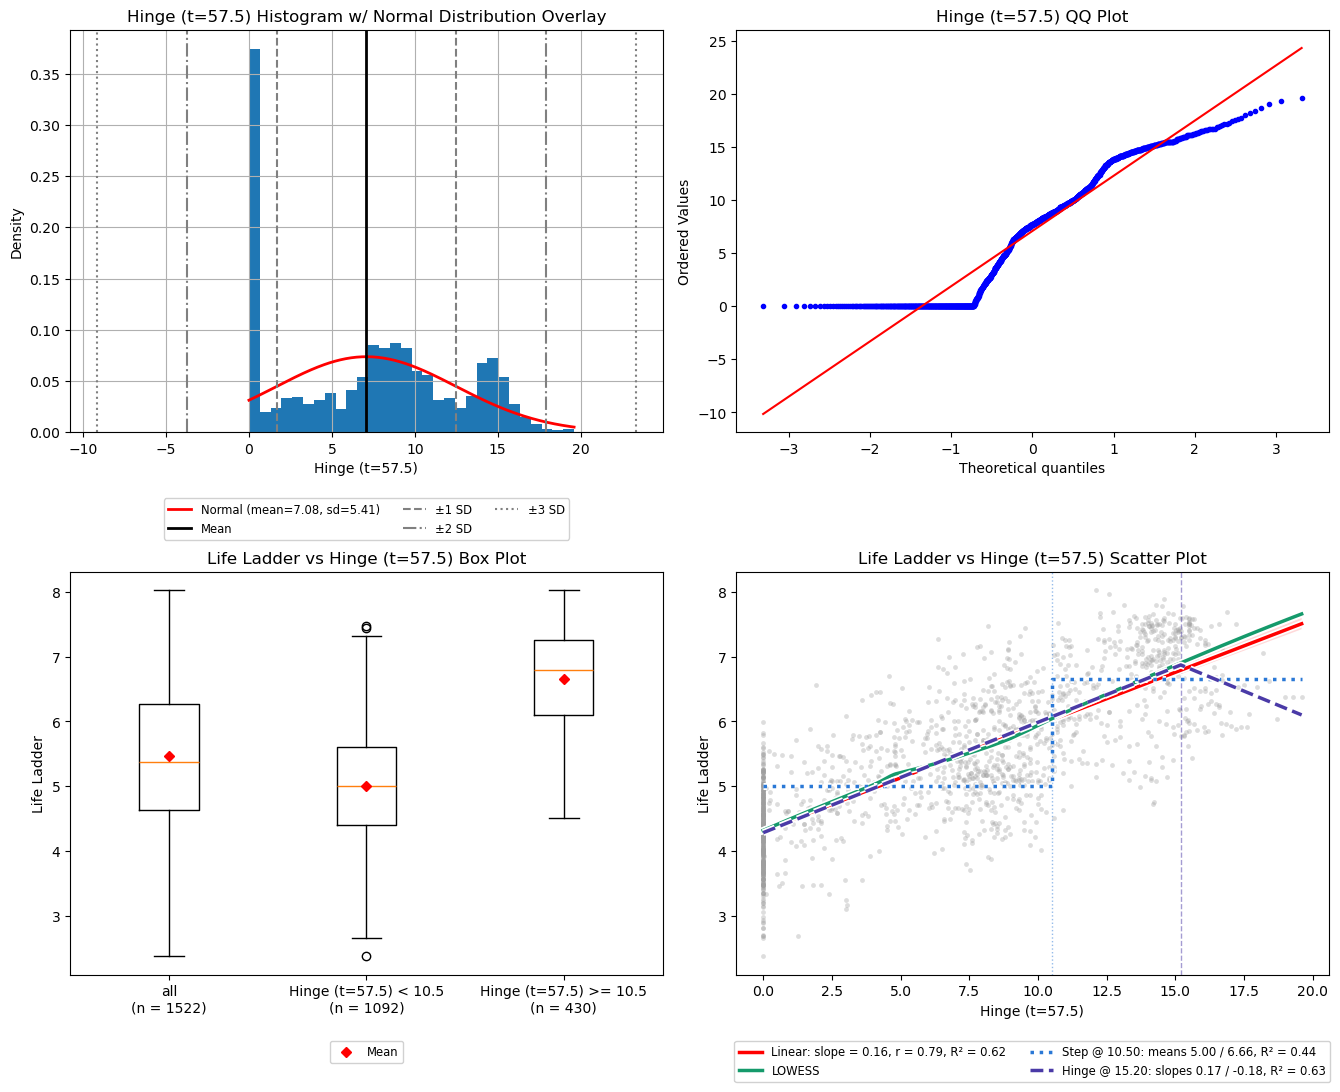

In [29]:
# fit on all hle_df rows, for illustration only (the scores below refit inside each training fold)
hle_b_df = pd.DataFrame(
	{"Hinge (t=57.5)": np.ravel(FEATURES.HighHinge(t=57.5).fit_transform(hle_X)), TARGET: hle_y},
	index=hle_df.index,
)
PLOTTING.single_feature_plots(df=hle_b_df, feature="Hinge (t=57.5)", target=TARGET, threshold="auto");

In [30]:
hle_b_pipeline = Pipeline([("features", FEATURES.HighHinge(t=57.5)), ("model", LinearRegression())])

hle_results["B fixed (t=57.5)"] = PIPELINES.evaluate_pipeline(
	hle_b_pipeline,
	X=hle_X, y=hle_y, folds=hle_folds,
)
hle_results["B nested"] = PIPELINES.evaluate_pipeline(
	FEATURES.nested_threshold(hle_b_pipeline, param="features__t", grid=hle_grid),
	X=hle_X, y=hle_y, folds=hle_folds, return_estimator=True,
)
display(SCORING.results_df({k: hle_results[k] for k in ["A", "B fixed (t=57.5)", "B nested"]}, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
B fixed (t=57.5),0.695,0.615,-0.046,0.010,candidate
B nested,0.695,0.614,-0.046,0.009,candidate
A,0.741,0.562,0.000,NaN,baseline


In [31]:
# threshold picked by the inner search in each of the 20 folds
hle_b_picked = FEATURES.picked_thresholds(hle_results["B nested"]["estimator"], param="features__t")
display(pd.Series(hle_b_picked).value_counts().sort_index().rename_axis("B nested picked t").to_frame("folds"))

,folds
B nested picked t,
56.5,6
57.0,11
57.5,3


#### Intervention C | Raw + hinge

`[x, max(0, x - t)]`

The same hinge as B with the raw column kept, which gives the fit a spare slope below t at the cost of an extra column.

In [32]:
hle_c_pipeline = Pipeline([("features", FEATURES.HighHinge(t=57.5, keep_raw=True)), ("model", LinearRegression())])

hle_results["C fixed (t=57.5)"] = PIPELINES.evaluate_pipeline(
	hle_c_pipeline,
	X=hle_X, y=hle_y, folds=hle_folds,
)
hle_results["C nested"] = PIPELINES.evaluate_pipeline(
	FEATURES.nested_threshold(hle_c_pipeline, param="features__t", grid=hle_grid),
	X=hle_X, y=hle_y, folds=hle_folds, return_estimator=True,
)
display(SCORING.results_df({k: hle_results[k] for k in ["A", "C fixed (t=57.5)", "C nested"]}, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
C fixed (t=57.5),0.695,0.615,-0.047,0.009,candidate
C nested,0.695,0.614,-0.046,0.009,candidate
A,0.741,0.562,0.000,NaN,baseline


In [33]:
# threshold picked by the inner search in each of the 20 folds
hle_c_picked = FEATURES.picked_thresholds(hle_results["C nested"]["estimator"], param="features__t")
display(pd.Series(hle_c_picked).value_counts().sort_index().rename_axis("C nested picked t").to_frame("folds"))

,folds
C nested picked t,
56.5,1
57.0,5
57.5,8
58.0,6


#### Comparison

In [34]:
display(SCORING.results_df(hle_results, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
C fixed (t=57.5),0.695,0.615,-0.047,0.009,candidate
B fixed (t=57.5),0.695,0.615,-0.046,0.010,candidate
B nested,0.695,0.614,-0.046,0.009,candidate
C nested,0.695,0.614,-0.046,0.009,candidate
A,0.741,0.562,0.000,NaN,baseline


#### Results

- **The hinge is a clear gain.** rmse falls from 0.741 to 0.695 in all four variants, and all four are candidates.
- **The raw column adds nothing next to the hinge.** B and C score the same rmse, as Q1B expected from the slope of 0.01 below the bend.
- **The bend is stable.** The nested picks stay between 56.5 and 58.0 in every fold, around Q1B's 57.5.

**Carry forward**

- **B (hinge alone)**, in place of the raw value.

**Ignore**

- **C (raw + hinge).** It matches B with an extra column.

### Negative Affect

**Q1B's top suggestion is to drop this attribute entirely.** A drop cannot be scored with a single attribute, so this section tests rank 2 as B, the shape to use if the attribute is kept: a hinge alone at 0.20 in place of the raw value.

In [35]:
na_col = COLUMNS['NA']['col']
na_df = train_df[[na_col, TARGET]].dropna(subset=[na_col])
na_X = na_df[[na_col]]
na_y = na_df[TARGET]

# Negative affect spans a narrow range, so the nested search uses its own grid over that range, in finer steps than FEATURES.THRESHOLD_GRID
na_grid = np.round(np.arange(0.08, 0.701, 0.01), 2)

na_folds = PIPELINES.make_folds(na_X, seeds=SEEDS)
na_results = {}

na_x = na_X[na_col].to_numpy()
na_guarded = [t for t in na_grid if min(np.mean(na_x < t), np.mean(na_x >= t)) >= FEATURES.MIN_GROUP_FRAC]
print(f"rows used: {len(na_df)} of {len(train_df)}")
print(f"folds: {len(na_folds)}")
print(f"threshold grid after the 5% guard (all rows): {na_guarded[0]} to {na_guarded[-1]}")

rows used: 1545 of 1559
folds: 20
threshold grid after the 5% guard (all rows): 0.16 to 0.41


#### Intervention A | Baseline (raw)

In [36]:
na_results["A"] = PIPELINES.evaluate_pipeline(
	Pipeline([("model", LinearRegression())]),
	X=na_X, y=na_y, folds=na_folds,
)
display(SCORING.results_df({k: na_results[k] for k in ["A"]}, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
A,1.064,0.088,0.0,NaN,baseline


#### Intervention B | Hinge alone

`[max(0, x - t)]`

Targets the bend in Q1B's LOWESS, flat or slightly rising up to about 0.2 and falling above, which Q1B's hinge fit places at 0.20 (slope 3.93 below, -5.21 above). Every row at or below t gets the same prediction.

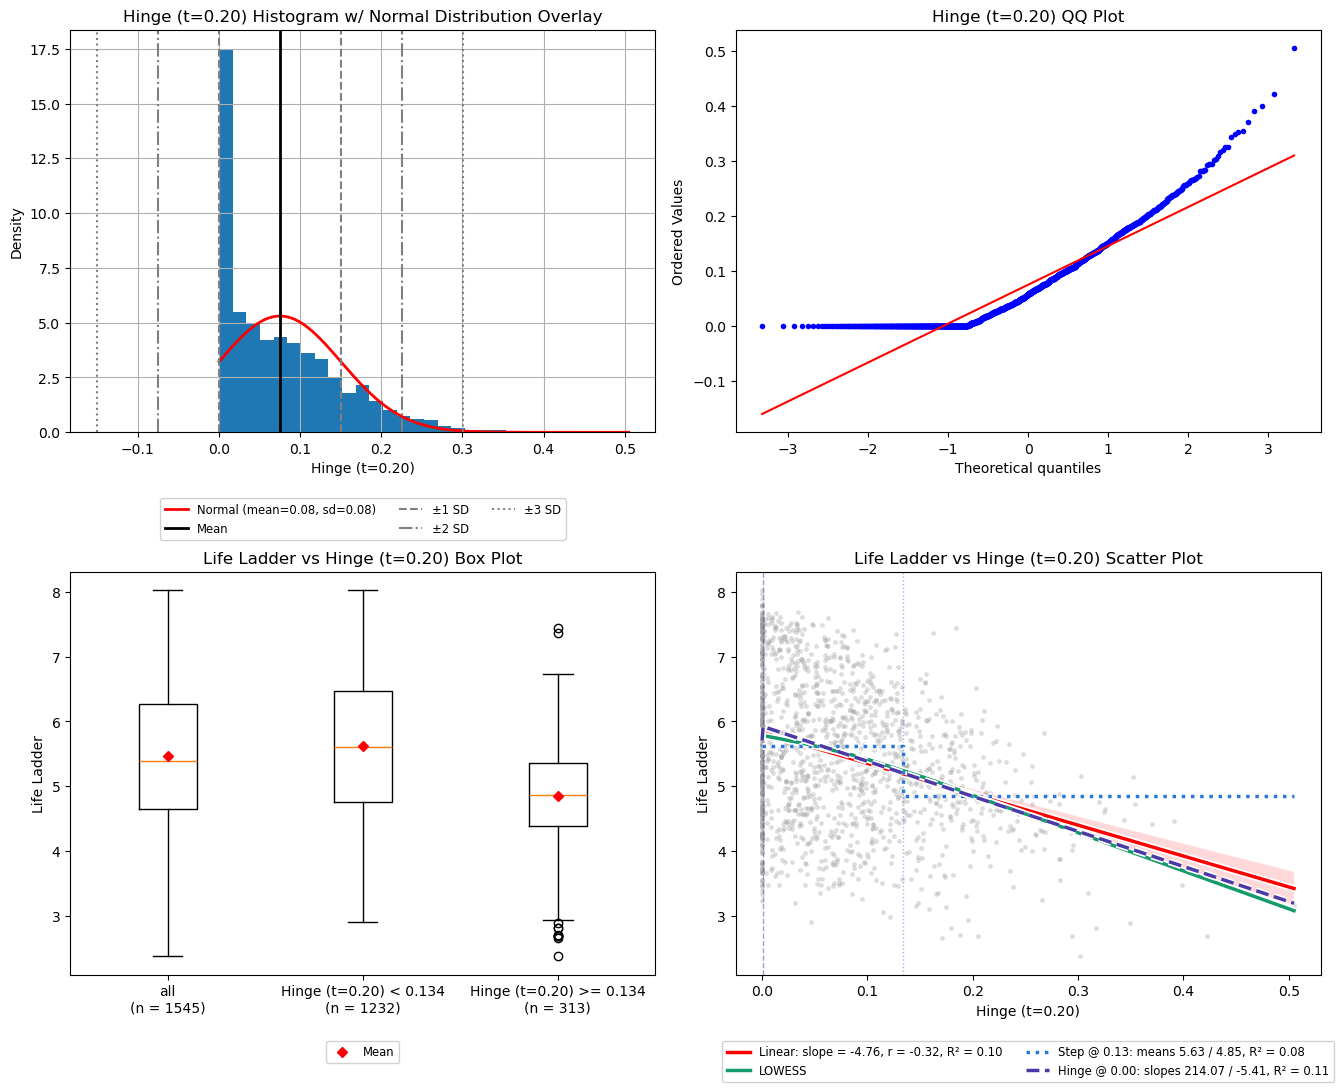

In [37]:
# fit on all na_df rows, for illustration only (the scores below refit inside each training fold)
na_b_df = pd.DataFrame(
	{"Hinge (t=0.20)": np.ravel(FEATURES.HighHinge(t=0.20).fit_transform(na_X)), TARGET: na_y},
	index=na_df.index,
)
PLOTTING.single_feature_plots(df=na_b_df, feature="Hinge (t=0.20)", target=TARGET, threshold="auto");

In [38]:
na_b_pipeline = Pipeline([("features", FEATURES.HighHinge(t=0.20)), ("model", LinearRegression())])

na_results["B fixed (t=0.20)"] = PIPELINES.evaluate_pipeline(
	na_b_pipeline,
	X=na_X, y=na_y, folds=na_folds,
)
na_results["B nested"] = PIPELINES.evaluate_pipeline(
	FEATURES.nested_threshold(na_b_pipeline, param="features__t", grid=na_grid),
	X=na_X, y=na_y, folds=na_folds, return_estimator=True,
)
display(SCORING.results_df({k: na_results[k] for k in ["A", "B fixed (t=0.20)", "B nested"]}, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
B fixed (t=0.20),1.057,0.100,-0.007,0.002,candidate
B nested,1.057,0.099,-0.007,0.004,candidate
A,1.064,0.088,0.000,NaN,baseline


In [39]:
# threshold picked by the inner search in each of the 20 folds
na_b_picked = FEATURES.picked_thresholds(na_results["B nested"]["estimator"], param="features__t")
display(pd.Series(na_b_picked).value_counts().sort_index().rename_axis("B nested picked t").to_frame("folds"))

,folds
B nested picked t,
0.21,4
0.22,3
0.23,11
0.24,1
0.26,1


#### Comparison

In [40]:
display(SCORING.results_df(na_results, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
B fixed (t=0.20),1.057,0.100,-0.007,0.002,candidate
B nested,1.057,0.099,-0.007,0.004,candidate
A,1.064,0.088,0.000,NaN,baseline


#### Results

- **The hinge beats the raw value in both variants.** rmse falls from 1.064 to 1.057, and both are candidates.
- **Searching t does not improve on Q1B's 0.20.** B nested picked t between 0.21 and 0.26 in every fold and scores the same rmse as B fixed.
- **The attribute stays weak either way.** r2 only rises from 0.088 to 0.100 (fixed) or 0.099 (nested), which supports Q1B's suggestion to drop it.

**Carry forward**

- **Dropping the attribute**, as the option to test first.
- **B (hinge alone)**, in place of the raw value, if the attribute is kept.

### Freedom to Make Life Choices

Tests Q1B's rank 1 as B (raw value plus a hinge near 0.80) and rank 2 as C (a transform that stretches only the top end, using `-log(1 - x)`, Q1B's first choice). Rank 4, the raw value alone, is A.

In [41]:
free_col = COLUMNS['FTMLC']['col']
free_df = train_df[[free_col, TARGET]].dropna(subset=[free_col])
free_X = free_df[[free_col]]
free_y = free_df[TARGET]

# Q1B's hinge at 0.80 is not on FEATURES.THRESHOLD_GRID, so the nested search uses its own grid over this attribute's range, in finer steps
free_grid = np.round(np.arange(0.26, 0.981, 0.01), 2)


def free_neg_log_one_minus(x):
	"""-log(1 - x), used by Intervention C."""
	return -np.log1p(-x)


free_folds = PIPELINES.make_folds(free_X, seeds=SEEDS)
free_results = {}

free_x = free_X[free_col].to_numpy()
free_guarded = [t for t in free_grid if min(np.mean(free_x < t), np.mean(free_x >= t)) >= FEATURES.MIN_GROUP_FRAC]
print(f"rows used: {len(free_df)} of {len(train_df)}")
print(f"folds: {len(free_folds)}")
print(f"threshold grid after the 5% guard (all rows): {free_guarded[0]} to {free_guarded[-1]}")

rows used: 1537 of 1559
folds: 20
threshold grid after the 5% guard (all rows): 0.48 to 0.93


#### Intervention A | Baseline (raw)

In [42]:
free_results["A"] = PIPELINES.evaluate_pipeline(
	Pipeline([("model", LinearRegression())]),
	X=free_X, y=free_y, folds=free_folds,
)
display(SCORING.results_df({k: free_results[k] for k in ["A"]}, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
A,0.949,0.276,0.0,NaN,baseline


#### Intervention B | Raw + hinge

`[x, max(0, x - t)]`

Targets the bend in Q1B's LOWESS, shallow below about 0.8 and steep above, which Q1B's hinge fit places at 0.80 (slope 2.35 below, 9.65 above).

In [43]:
free_b_pipeline = Pipeline([("features", FEATURES.HighHinge(t=0.80, keep_raw=True)), ("model", LinearRegression())])

free_results["B fixed (t=0.80)"] = PIPELINES.evaluate_pipeline(
	free_b_pipeline,
	X=free_X, y=free_y, folds=free_folds,
)
free_results["B nested"] = PIPELINES.evaluate_pipeline(
	FEATURES.nested_threshold(free_b_pipeline, param="features__t", grid=free_grid),
	X=free_X, y=free_y, folds=free_folds, return_estimator=True,
)
display(SCORING.results_df({k: free_results[k] for k in ["A", "B fixed (t=0.80)", "B nested"]}, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
B fixed (t=0.80),0.921,0.318,-0.028,0.011,candidate
B nested,0.923,0.315,-0.026,0.010,candidate
A,0.949,0.276,0.000,NaN,baseline


In [44]:
# threshold picked by the inner search in each of the 20 folds
free_b_picked = FEATURES.picked_thresholds(free_results["B nested"]["estimator"], param="features__t")
display(pd.Series(free_b_picked).value_counts().sort_index().rename_axis("B nested picked t").to_frame("folds"))

,folds
B nested picked t,
0.77,2
0.78,5
0.79,1
0.80,4
0.81,4
0.82,4


#### Intervention C | -log(1 - x)

`[-log(1 - x)]`

Targets the same bend with one column and no threshold. The transform stretches only the top end, where Q1B's LOWESS is steep, and has nothing to fit.

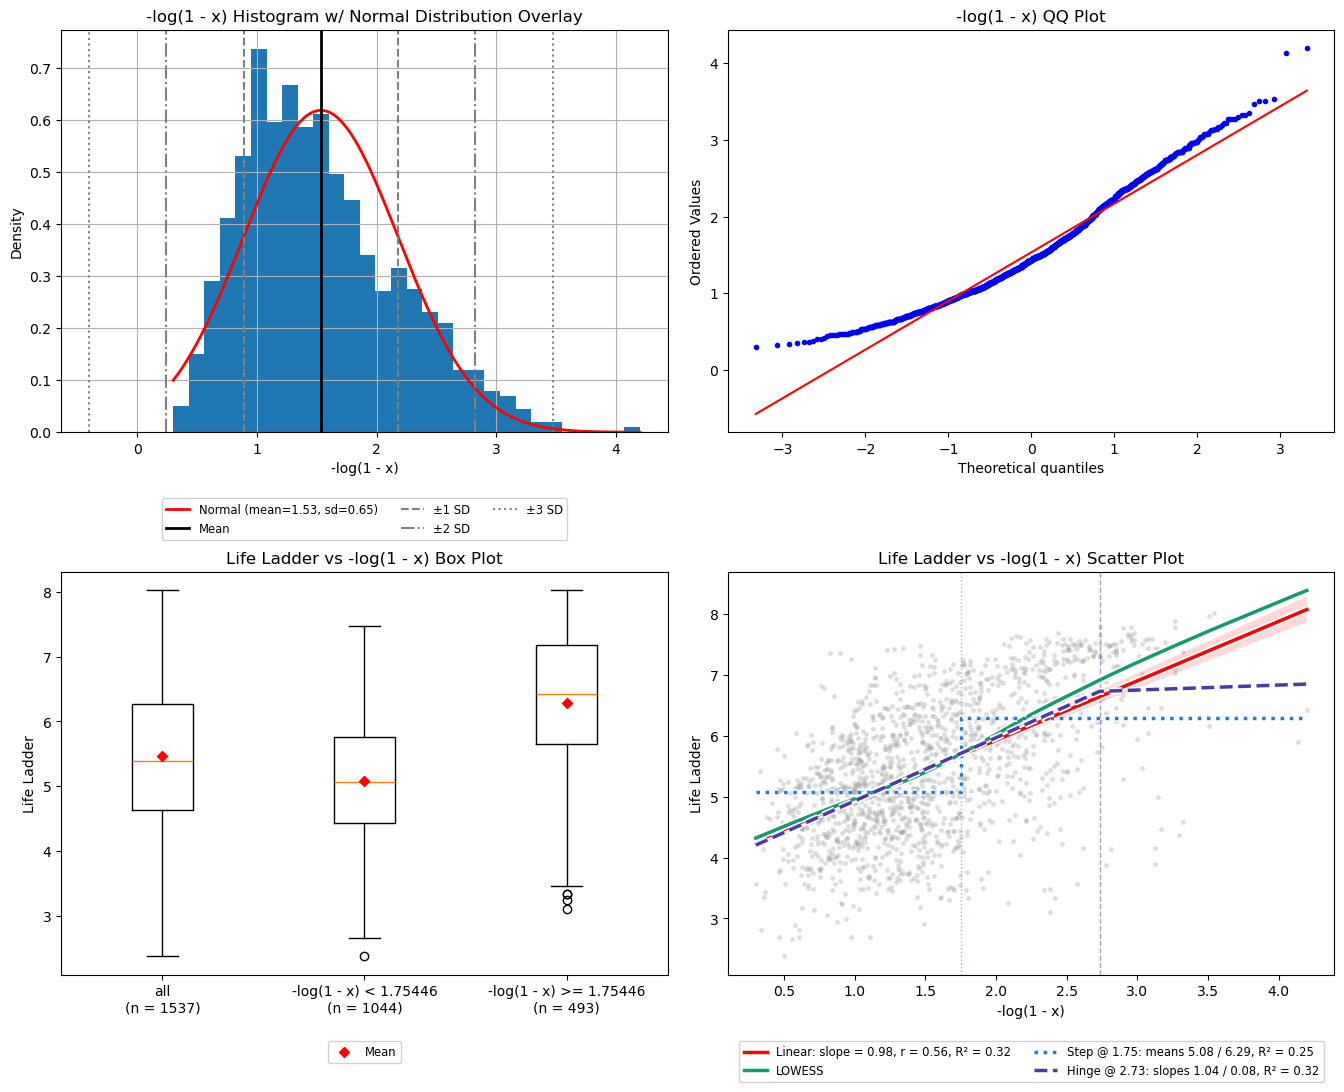

In [45]:
# fit on all free_df rows, for illustration only (the scores below refit inside each training fold)
free_c_df = pd.DataFrame(
	{"-log(1 - x)": np.ravel(FunctionTransformer(free_neg_log_one_minus).fit_transform(free_X)), TARGET: free_y},
	index=free_df.index,
)
PLOTTING.single_feature_plots(df=free_c_df, feature="-log(1 - x)", target=TARGET, threshold="auto");

In [46]:
free_results["C"] = PIPELINES.evaluate_pipeline(
	Pipeline([("features", FunctionTransformer(free_neg_log_one_minus)), ("model", LinearRegression())]),
	X=free_X, y=free_y, folds=free_folds,
)
display(SCORING.results_df({k: free_results[k] for k in ["A", "C"]}, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
C,0.924,0.313,-0.025,0.009,candidate
A,0.949,0.276,0.000,NaN,baseline


#### Comparison

In [47]:
display(SCORING.results_df(free_results, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
B fixed (t=0.80),0.921,0.318,-0.028,0.011,candidate
B nested,0.923,0.315,-0.026,0.010,candidate
C,0.924,0.313,-0.025,0.009,candidate
A,0.949,0.276,0.000,NaN,baseline


#### Results

- **Both treatments fix the bend, and all three variants are candidates.** rmse falls from 0.949 to 0.921 (B fixed), 0.923 (B nested) and 0.924 (C).
- **The hinge location is stable.** B nested picked t between 0.77 and 0.82 in every fold, around Q1B's 0.80.
- **The scores do not separate B and C.** They differ only in the third decimal of rmse, and C gets there with one column and no threshold.

**Carry forward**

- **B (raw + hinge)**, Q1B's rank 1.
- **C (`-log(1 - x)`)** as the alternative, not together with B: both straighten the same bend.

### Positive Affect

**Q1B's top suggestion is to leave this attribute alone**, so here A (the raw value) is Q1B's rank 1. Rank 2, one extra term for the rise between about 0.71 and 0.75, is tested in both of its forms: an indicator at 0.749 as B and a hinge at 0.71 as C.

In [48]:
pa_col = COLUMNS['PA']['col']
pa_df = train_df[[pa_col, TARGET]].dropna(subset=[pa_col])
pa_X = pa_df[[pa_col]]
pa_y = pa_df[TARGET]

# the nested search uses its own grid over this attribute's range, in finer steps than FEATURES.THRESHOLD_GRID
pa_grid = np.round(np.arange(0.32, 0.941, 0.01), 2)

pa_folds = PIPELINES.make_folds(pa_X, seeds=SEEDS)
pa_results = {}

pa_x = pa_X[pa_col].to_numpy()
pa_guarded = [t for t in pa_grid if min(np.mean(pa_x < t), np.mean(pa_x >= t)) >= FEATURES.MIN_GROUP_FRAC]
print(f"rows used: {len(pa_df)} of {len(train_df)}")
print(f"folds: {len(pa_folds)}")
print(f"threshold grid after the 5% guard (all rows): {pa_guarded[0]} to {pa_guarded[-1]}")

rows used: 1542 of 1559
folds: 20
threshold grid after the 5% guard (all rows): 0.53 to 0.86


#### Intervention A | Baseline (raw)

In [49]:
pa_results["A"] = PIPELINES.evaluate_pipeline(
	Pipeline([("model", LinearRegression())]),
	X=pa_X, y=pa_y, folds=pa_folds,
)
display(SCORING.results_df({k: pa_results[k] for k in ["A"]}, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
A,0.944,0.282,0.0,NaN,baseline


#### Intervention B | Raw + indicator

`[x, 1 if x < t else 0]`

Targets the rise as a level shift: in Q1B's box plot, the 641 rows at or above 0.749 have a median Life Ladder of about 6.3, vs about 5.0 for the 901 rows below.

In [50]:
pa_b_pipeline = Pipeline([("features", FEATURES.Indicator(t=0.749, keep_raw=True)), ("model", LinearRegression())])

pa_results["B fixed (t=0.749)"] = PIPELINES.evaluate_pipeline(
	pa_b_pipeline,
	X=pa_X, y=pa_y, folds=pa_folds,
)
pa_results["B nested"] = PIPELINES.evaluate_pipeline(
	FEATURES.nested_threshold(pa_b_pipeline, param="features__t", grid=pa_grid),
	X=pa_X, y=pa_y, folds=pa_folds, return_estimator=True,
)
display(SCORING.results_df({k: pa_results[k] for k in ["A", "B fixed (t=0.749)", "B nested"]}, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
B fixed (t=0.749),0.933,0.298,-0.011,0.004,candidate
B nested,0.936,0.294,-0.008,0.004,candidate
A,0.944,0.282,0.000,NaN,baseline


In [51]:
# threshold picked by the inner search in each of the 20 folds
pa_b_picked = FEATURES.picked_thresholds(pa_results["B nested"]["estimator"], param="features__t")
display(pd.Series(pa_b_picked).value_counts().sort_index().rename_axis("B nested picked t").to_frame("folds"))

,folds
B nested picked t,
0.67,1
0.75,17
0.78,2


#### Intervention C | Raw + hinge

`[x, max(0, x - t)]`

Targets the rise as a change of slope: Q1B's LOWESS steepens slightly above about 0.71 (hinge slopes 3.59 / 8.09).

In [52]:
pa_c_pipeline = Pipeline([("features", FEATURES.HighHinge(t=0.71, keep_raw=True)), ("model", LinearRegression())])

pa_results["C fixed (t=0.71)"] = PIPELINES.evaluate_pipeline(
	pa_c_pipeline,
	X=pa_X, y=pa_y, folds=pa_folds,
)
pa_results["C nested"] = PIPELINES.evaluate_pipeline(
	FEATURES.nested_threshold(pa_c_pipeline, param="features__t", grid=pa_grid),
	X=pa_X, y=pa_y, folds=pa_folds, return_estimator=True,
)
display(SCORING.results_df({k: pa_results[k] for k in ["A", "C fixed (t=0.71)", "C nested"]}, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
C fixed (t=0.71),0.936,0.294,-0.008,0.003,candidate
C nested,0.936,0.294,-0.008,0.003,candidate
A,0.944,0.282,0.000,NaN,baseline


In [53]:
# threshold picked by the inner search in each of the 20 folds
pa_c_picked = FEATURES.picked_thresholds(pa_results["C nested"]["estimator"], param="features__t")
display(pd.Series(pa_c_picked).value_counts().sort_index().rename_axis("C nested picked t").to_frame("folds"))

,folds
C nested picked t,
0.70,1
0.71,13
0.72,5
0.73,1


#### Comparison

In [54]:
display(SCORING.results_df(pa_results, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
B fixed (t=0.749),0.933,0.298,-0.011,0.004,candidate
C fixed (t=0.71),0.936,0.294,-0.008,0.003,candidate
B nested,0.936,0.294,-0.008,0.004,candidate
C nested,0.936,0.294,-0.008,0.003,candidate
A,0.944,0.282,0.000,NaN,baseline


#### Results

- **Both extra terms beat the raw column, but by a small margin.** All four variants are candidates, yet the best one (B fixed) only lowers rmse from 0.944 to 0.933.
- **The scores do not separate the indicator and the hinge.** B leads only at Q1B's exact 0.749. With t searched, B and C tie at rmse 0.936.
- **Both thresholds are stable.** B nested picked 0.75 in 17 of the 20 folds, and C nested picked t between 0.70 and 0.73 in every fold.

**Carry forward**

- **B (raw + indicator)**, with **C (raw + hinge)** as the alternative, not together: both are forms of the one extra term Q1B suggested.
- **The raw value alone (A)** as the fallback, per Q1B's rank 1, if neither extra term holds up once the other attributes are in the model.

### Log GDP per Capita

Tests both forms of Q1B's rank 1 (raw value plus piecewise linear terms above 10): one hinge near 10.13 as B and two hinges as C. Rank 2, raw value plus an indicator for the high cluster at about 10.4, is D.

In [55]:
gdp_col = COLUMNS['LGDP']['col']
gdp_df = train_df[[gdp_col, TARGET]].dropna(subset=[gdp_col])
gdp_X = gdp_df[[gdp_col]]
gdp_y = gdp_df[TARGET]

# the nested searches use their own grids over this attribute's range: single thresholds, and (t1, t2) pairs with t1 < t2 for C
gdp_grid = np.round(np.arange(6.60, 11.651, 0.01), 2)
gdp_pair_values = np.round(np.arange(6.6, 11.651, 0.1), 1)
gdp_pair_grid = [(t1, t2) for t1 in gdp_pair_values for t2 in gdp_pair_values if t1 < t2]

gdp_folds = PIPELINES.make_folds(gdp_X, seeds=SEEDS)
gdp_results = {}

gdp_x = gdp_X[gdp_col].to_numpy()
gdp_guarded = [t for t in gdp_grid if min(np.mean(gdp_x < t), np.mean(gdp_x >= t)) >= FEATURES.MIN_GROUP_FRAC]
gdp_pair_guarded = [t for t in gdp_pair_values if min(np.mean(gdp_x < t), np.mean(gdp_x >= t)) >= FEATURES.MIN_GROUP_FRAC]
print(f"rows used: {len(gdp_df)} of {len(train_df)}")
print(f"folds: {len(gdp_folds)}")
print(f"threshold grid after the 5% guard (all rows): {gdp_guarded[0]} to {gdp_guarded[-1]}")
print(f"pair grid after the 5% guard (all rows): {gdp_pair_guarded[0]} to {gdp_pair_guarded[-1]}")

rows used: 1533 of 1559
folds: 20
threshold grid after the 5% guard (all rows): 7.37 to 10.94
pair grid after the 5% guard (all rows): 7.4 to 10.9


#### Intervention A | Baseline (raw)

In [56]:
gdp_results["A"] = PIPELINES.evaluate_pipeline(
	Pipeline([("model", LinearRegression())]),
	X=gdp_X, y=gdp_y, folds=gdp_folds,
)
display(SCORING.results_df({k: gdp_results[k] for k in ["A"]}, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
A,0.687,0.617,0.0,NaN,baseline


#### Intervention B | Raw + hinge

`[x, max(0, x - t)]`

Targets the bend in Q1B's LOWESS, which tracks the straight line up to about 10 and then steepens. Q1B's hinge fit places it at 10.13 (slope 0.62 below, 1.31 above).

In [57]:
gdp_b_pipeline = Pipeline([("features", FEATURES.HighHinge(t=10.13, keep_raw=True)), ("model", LinearRegression())])

gdp_results["B fixed (t=10.13)"] = PIPELINES.evaluate_pipeline(
	gdp_b_pipeline,
	X=gdp_X, y=gdp_y, folds=gdp_folds,
)
gdp_results["B nested"] = PIPELINES.evaluate_pipeline(
	FEATURES.nested_threshold(gdp_b_pipeline, param="features__t", grid=gdp_grid),
	X=gdp_X, y=gdp_y, folds=gdp_folds, return_estimator=True,
)
display(SCORING.results_df({k: gdp_results[k] for k in ["A", "B fixed (t=10.13)", "B nested"]}, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
B fixed (t=10.13),0.670,0.636,-0.017,0.004,candidate
B nested,0.670,0.636,-0.017,0.004,candidate
A,0.687,0.617,0.000,NaN,baseline


In [58]:
# threshold picked by the inner search in each of the 20 folds
gdp_b_picked = FEATURES.picked_thresholds(gdp_results["B nested"]["estimator"], param="features__t")
display(pd.Series(gdp_b_picked).value_counts().sort_index().rename_axis("B nested picked t").to_frame("folds"))

,folds
B nested picked t,
10.03,1
10.10,1
10.11,1
10.12,6
10.13,5
10.14,4
10.15,1
10.17,1


#### Intervention C | Raw + two hinges

`[x, max(0, x - t1), max(0, x - t2)]`

Targets the top end, where Q1B's points above about 11.2 appear to fall back below the hinge line. Q1B gives no fitted value for the second bend, so there is no fixed variant: the pair is always searched.

In [59]:
# both t values below are placeholders, the nested search sets the pair in each fold
gdp_c_pipeline = Pipeline([
	("features", FeatureUnion([("low", FEATURES.HighHinge(t=10.13, keep_raw=True)), ("high", FEATURES.HighHinge(t=11.0))])),
	("model", LinearRegression()),
])

gdp_results["C nested"] = PIPELINES.evaluate_pipeline(
	FEATURES.nested_threshold(gdp_c_pipeline, param=("features__low__t", "features__high__t"), grid=gdp_pair_grid),
	X=gdp_X, y=gdp_y, folds=gdp_folds, return_estimator=True,
)
display(SCORING.results_df({k: gdp_results[k] for k in ["A", "C nested"]}, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
C nested,0.652,0.655,-0.036,0.006,candidate
A,0.687,0.617,0.000,NaN,baseline


In [60]:
# (t1, t2) pair picked by the inner search in each of the 20 folds, sorted as numbers before formatting
gdp_c_picked = sorted(FEATURES.picked_thresholds(gdp_results["C nested"]["estimator"], param=("features__low__t", "features__high__t")))
gdp_c_picked = [f"({t1:.1f}, {t2:.1f})" for t1, t2 in gdp_c_picked]
display(pd.Series(gdp_c_picked).value_counts(sort=False).rename_axis("C nested picked (t1, t2)").to_frame("folds"))

,folds
"C nested picked (t1, t2)",
"(10.3, 10.8)",2
"(10.3, 10.9)",15
"(10.4, 10.8)",3


#### Intervention D | Raw + indicator

`[x, 1 if x < t else 0]`

Targets the rise as a jump: in Q1B, a dense cluster of rows above about 10.4 sits above the straight line. The column is 1 below t, the same split as Q1B's high cluster indicator with the coefficient's sign flipped.

In [61]:
gdp_d_pipeline = Pipeline([("features", FEATURES.Indicator(t=10.4, keep_raw=True)), ("model", LinearRegression())])

gdp_results["D fixed (t=10.4)"] = PIPELINES.evaluate_pipeline(
	gdp_d_pipeline,
	X=gdp_X, y=gdp_y, folds=gdp_folds,
)
gdp_results["D nested"] = PIPELINES.evaluate_pipeline(
	FEATURES.nested_threshold(gdp_d_pipeline, param="features__t", grid=gdp_grid),
	X=gdp_X, y=gdp_y, folds=gdp_folds, return_estimator=True,
)
display(SCORING.results_df({k: gdp_results[k] for k in ["A", "D fixed (t=10.4)", "D nested"]}, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
D nested,0.660,0.647,-0.028,0.006,candidate
D fixed (t=10.4),0.660,0.647,-0.028,0.006,candidate
A,0.687,0.617,0.000,NaN,baseline


In [62]:
# threshold picked by the inner search in each of the 20 folds
gdp_d_picked = FEATURES.picked_thresholds(gdp_results["D nested"]["estimator"], param="features__t")
display(pd.Series(gdp_d_picked).value_counts().sort_index().rename_axis("D nested picked t").to_frame("folds"))

,folds
D nested picked t,
10.42,8
10.45,7
10.47,3
10.48,1
10.52,1


#### Comparison

In [63]:
display(SCORING.results_df(gdp_results, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
C nested,0.652,0.655,-0.036,0.006,candidate
D nested,0.660,0.647,-0.028,0.006,candidate
D fixed (t=10.4),0.660,0.647,-0.028,0.006,candidate
B fixed (t=10.13),0.670,0.636,-0.017,0.004,candidate
B nested,0.670,0.636,-0.017,0.004,candidate
A,0.687,0.617,0.000,NaN,baseline


#### Results

- **All three shapes beat A and are candidates.** rmse falls from 0.687 to 0.670 (B), 0.660 (D) and 0.652 (C).
- **With one extra column, the jump scores better than the bend.** D has a lower rmse than B, and both thresholds are stable: D nested picked t between 10.42 and 10.52 and B nested between 10.03 and 10.17 in every fold.
- **The second bend scores best, with a caution.** C put t2 at 10.9, the top of the guarded pair range, in 15 of the 20 folds (10.8 in the rest), so its search may be capped by the 5% guard.

**Carry forward**

- **C (raw + two hinges).** Recheck that it still leads D once the other attributes are in the model, since its lead rests on a threshold at the edge of the guard.
- **D (raw + indicator)** as the alternative: one extra column and one stable threshold.

**Ignore**

- **B (raw + one hinge).** D scores better with the same number of columns.